# KQC SampleHolderTest — 40 RF launchers joined pairwise by 20 CPWs (Quantcore PDK rebuild)

**What the chip is.** **Source:** KQCircuits `chips/sample_holder_test.py` (`SampleHolderTest`, default parameters, chip name "CTest"),
© IQM Finland Oy, GPL-3.0 (`other-libs/KQCircuits-main/.../kqcircuits/chips/sample_holder_test.py`,
<https://github.com/iqm-finland/KQCircuits>). Spec: `docs/designs/kqc/test_chips.md` (row *SampleHolderTest*).

A sample-holder test: 40 RF launchers (pad width 160 µm, gap 96 µm, 520 µm from the chip edge, pitch 635 µm), ten
per side, and 20 CPWs that join them in pairs. PL-1 … PL-10 run from the north pads (left → right) to the east pads
(bottom → top), PL-11 … PL-20 from the south pads (right → left) to the west pads (top → bottom); each goes 1200 µm
straight in from both launcher corners and diagonally between, so the 20 lines are nested.

**Kept exactly (same KQC cells, parameters and positions):** KQC's `produce_n_launchers(40, "RF", 160, 96,
520, 635)`: 40 `Launcher(s = l = a_launcher = 160, b_launcher = launcher_frame_gap = 96)` cells at KQC's positions
(port ids clockwise from the top-left pad, as KQC numbers them) with KQC's names; the 20 lines as Designer routes
with KQC's nodes (launcher port → corner ± 1200 µm → other corner ± 1200 µm → port). Step 14 XORs the chip with a stand-alone KQC build.

**Substituted:** the launchers are 40 `Launcher` instances (`PL<i>_IN.port` / `PL<i>_OUT.port`) instead of chip
launchers (`launchers=`): the Designer's chip launchers know the sample holders SMA8, ARD24 and DC24 only (open request). The cells, parameters and positions are KQC's, so the layout is the same; the LOM sees
the same 50 Ω ports.

**This rebuild on the Quantcore PDK** (not a replica; we distribute it under GPL-3.0):

| topic | KQC source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 10 × 10 mm, KQC `ChipFrame` | same 10 × 10 mm, Quantcore die frame (L dicing markers, 3 × 3 alignment grids, chip boundary, device ID "CTest") |
| launchers | 40 RF launchers (`produce_n_launchers`), outer etch 104 µm from the edge | the same 40 `Launcher` cells with `edge="auto"`: outer etch `frame.pad_edge` = 100 µm from the edge (4 µm further out) |
| substrate | silicon (KQC simulation default) | sapphire 650 µm, εr 10.25 |
| junctions | none | none |
| cheese | KQC's whole-area ground grid (`with_grid`, in KQC's mask builds) | **the original wins:** KQC's grid (`with_grid=True`), so no PDK band |
| elements, positions, routes | — | kept: KQC's cells, parameters, positions and paths; waypoints from the launcher ports |
| placement | centred | centred (checked in step 6, no shift) |

The notebook walks through the build step by step: setup and the PDK → die and frame → launchers → components and
routes → DRC → netlist → LOM → FEM → results back → one design change → fab export → snapshots → summary. Steps
with nothing to act on say so.

## 1 · Setup

`LIVE` follows `QCC_LIVE` (default on: KLayout opens and redraws after every change; `QCC_LIVE=0` for batch
runs). `RUN_FEM = False` keeps the FEM step at "export only"; `True` solves the jobs in a new batch AEDT
2024 R1 (if installed). `FULL_FAB = False` skips the fab-only corner rounding in the fab step (the KQC grid has ≈ 0.9 M holes on 1/0 and 3/0) (`qcc mask` writes the full file).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer
from kqcircuits.pya_resolver import pya

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
RUN_FEM = False                                  # True: solve the exported jobs in a new batch AEDT 2024 R1
FULL_FAB = False                                 # True: also round the corners in the fab export (slow here)
OUT = Path("examples/designs/kqc/test_chips")                 # design JSON + final snapshots
STEPS = Path("build/snapshots/sample_holder_test")  # step-by-step snapshots (build/ is not kept in the repo)

## 2 · The PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

This chip has no junctions; it uses the stack, the frame and pad rule, the cheese / 3/0 rules and the fab layer map.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## 3 · The die and its frame

`Designer(...)` starts the 10 × 10 mm chip with the chip name "CTest" (the device ID); the 40 launchers are cells placed in step 4. `with_grid=True`
asks for KQC's whole-area ground grid (the original's cheese): the PDK band is then not added. The frame is the PDK
default (L dicing markers 1000/0, 3 × 3 alignment grids 1001/0, boundary 100/0); KQC's own `ChipFrame` is not drawn.

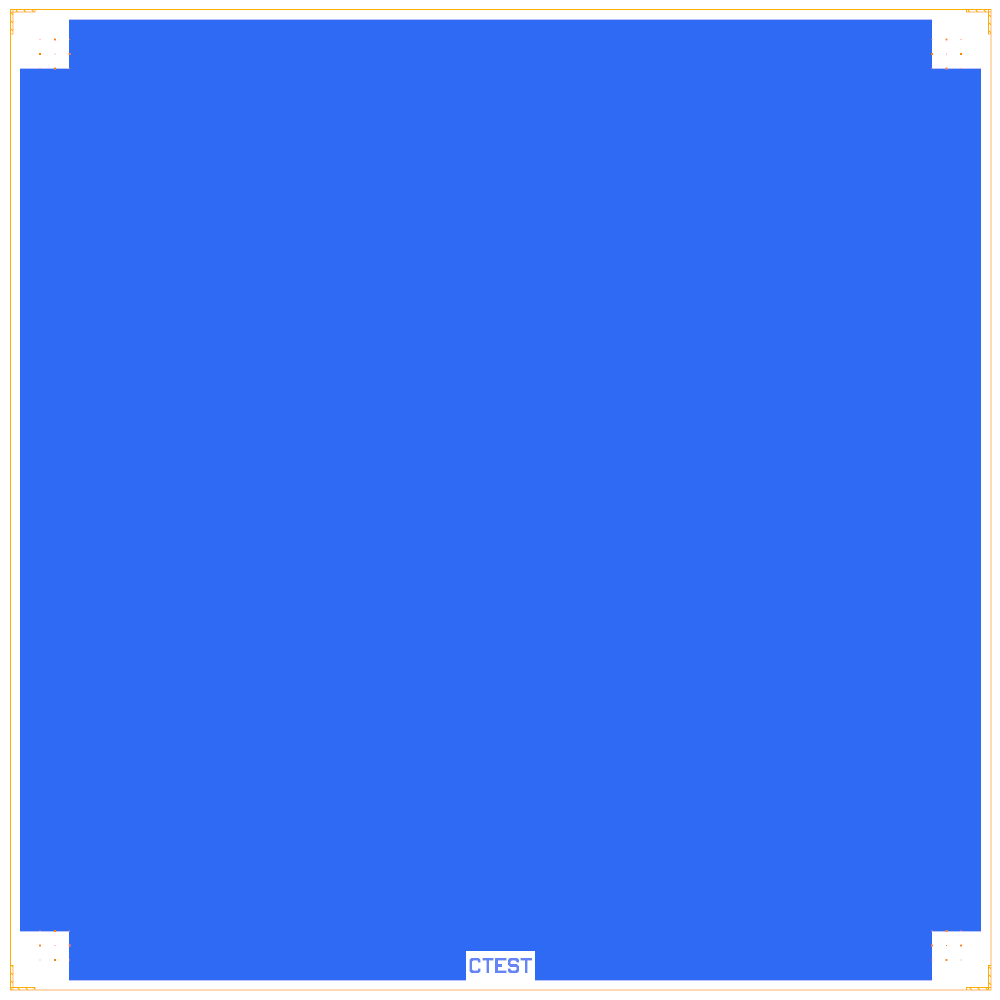

In [4]:
d = Designer("sample_holder_test", box=(0, 0, 10000, 10000), chip={"name_chip": "CTest", "with_grid": True},
             live=LIVE)
snap(d, STEPS / "1_die.png", box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420);

## 4 · Launchers and the pad rule

KQC's `produce_n_launchers(40, "RF", 160, 96, 520, 635)`: ten RF launchers per side on a 635 µm pitch, as 40
`Launcher` cells (pad and taper 160 µm, gap 96 µm) with KQC's names and port ids (clockwise from the top-left pad).
KQC puts their ports 520 µm in, so the outer etch edge ends 520 − 160 − 160 − 96 = 104 µm from the die edge.
**PDK rule:** the outer etch edge sits `frame.pad_edge` (100 µm) from the die edge; `edge="auto"` in `d.add` slides
each launcher perpendicular to its edge until it does (4 µm out). The table measures the result. (The Designer's
chip launchers know the SMA8, ARD24 and DC24 holders only, so the 40 are placed as cells.)

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| PL1_IN | `Launcher` | n | 100.0 | ✓ |
| PL2_IN | `Launcher` | n | 100.0 | ✓ |
| PL3_IN | `Launcher` | n | 100.0 | ✓ |
| PL4_IN | `Launcher` | n | 100.0 | ✓ |
| PL5_IN | `Launcher` | n | 100.0 | ✓ |
| PL6_IN | `Launcher` | n | 100.0 | ✓ |
| PL7_IN | `Launcher` | n | 100.0 | ✓ |
| PL8_IN | `Launcher` | n | 100.0 | ✓ |
| PL9_IN | `Launcher` | n | 100.0 | ✓ |
| PL10_IN | `Launcher` | n | 100.0 | ✓ |
| PL10_OUT | `Launcher` | e | 100.0 | ✓ |
| PL9_OUT | `Launcher` | e | 100.0 | ✓ |
| PL8_OUT | `Launcher` | e | 100.0 | ✓ |
| PL7_OUT | `Launcher` | e | 100.0 | ✓ |
| PL6_OUT | `Launcher` | e | 100.0 | ✓ |
| PL5_OUT | `Launcher` | e | 100.0 | ✓ |
| PL4_OUT | `Launcher` | e | 100.0 | ✓ |
| PL3_OUT | `Launcher` | e | 100.0 | ✓ |
| PL2_OUT | `Launcher` | e | 100.0 | ✓ |
| PL1_OUT | `Launcher` | e | 100.0 | ✓ |
| PL11_OUT | `Launcher` | s | 100.0 | ✓ |
| PL12_OUT | `Launcher` | s | 100.0 | ✓ |
| PL13_OUT | `Launcher` | s | 100.0 | ✓ |
| PL14_OUT | `Launcher` | s | 100.0 | ✓ |
| PL15_OUT | `Launcher` | s | 100.0 | ✓ |
| PL16_OUT | `Launcher` | s | 100.0 | ✓ |
| PL17_OUT | `Launcher` | s | 100.0 | ✓ |
| PL18_OUT | `Launcher` | s | 100.0 | ✓ |
| PL19_OUT | `Launcher` | s | 100.0 | ✓ |
| PL20_OUT | `Launcher` | s | 100.0 | ✓ |
| PL20_IN | `Launcher` | w | 100.0 | ✓ |
| PL19_IN | `Launcher` | w | 100.0 | ✓ |
| PL18_IN | `Launcher` | w | 100.0 | ✓ |
| PL17_IN | `Launcher` | w | 100.0 | ✓ |
| PL16_IN | `Launcher` | w | 100.0 | ✓ |
| PL15_IN | `Launcher` | w | 100.0 | ✓ |
| PL14_IN | `Launcher` | w | 100.0 | ✓ |
| PL13_IN | `Launcher` | w | 100.0 | ✓ |
| PL12_IN | `Launcher` | w | 100.0 | ✓ |
| PL11_IN | `Launcher` | w | 100.0 | ✓ |

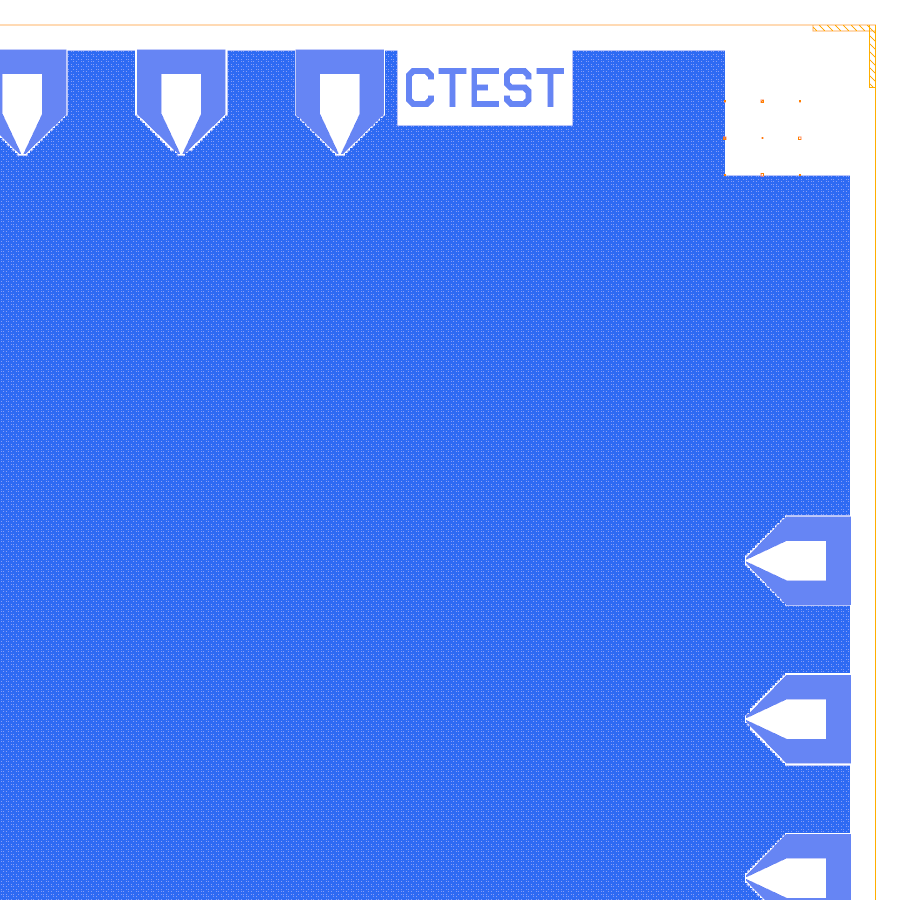

In [5]:
n, pitch, width, gap, indent, side, r = 40, 635, 160, 96, 520, 10000, 100   # KQC defaults; chip 10 mm, turn radius
per = n // 4
launcher = dict(s=width, l=width, a_launcher=width, b_launcher=gap, launcher_frame_gap=gap)
# KQC produce_n_launchers: per side a chip-box transform; u runs along the side, pads face inward
sides = [(lambda u: (u, side - indent), 90),             # north, left → right (port ids 1 … 10)
         (lambda u: (side - indent, side - u), 0),       # east, top → bottom (11 … 20)
         (lambda u: (side - u, indent), 270),            # south, right → left (21 … 30)
         (lambda u: (indent, u), 180)]                   # west, bottom → top (31 … 40)
name_of = {}                                             # KQC launcher_assignments
for i in range(1, per + 1):
    name_of[i] = f"PL{i}_IN"
    name_of[2 * per + 1 - i] = f"PL{i}_OUT"
    name_of[2 * per + i] = f"PL{per + i}_OUT"
    name_of[4 * per + 1 - i] = f"PL{per + i}_IN"
with d.batch():
    pid = 0
    for pos, rot in sides:
        for i in range(per):
            pid += 1
            d.add(name_of[pid], "Launcher", at=pos(side / 2 + pitch * (i + 0.5 - per / 2)), rot=rot, edge="auto",
                  **launcher)
rebuild(d)                                       # a live=False Designer builds on request: the table reads this build
display(Markdown(pads_md(d)))
snap(d, STEPS / "2_launchers.png", box=(6500, 6500, 10100, 10100), size=(900, 900), width=360);

## 5 · Components

The 40 launchers are the only components (step 4).

## 6 · Routes

The 20 lines join the launchers in pairs: PL-1 … PL-10 from the north pads (left → right) to the east pads
(bottom → top), PL-11 … PL-20 from the south pads (right → left) to the west pads (top → bottom). Each goes 1200 µm
straight in from both launcher corners and diagonally between, so the 20 lines are nested (KQC's
`_produce_waveguide(i, ∓1200, …)`). `corner(ref, shift)` is KQC's `"<port>_corner"` refpoint (one turn radius in)
plus a shift; the ports are read after the pad rule moved the launchers, so the lines follow them.

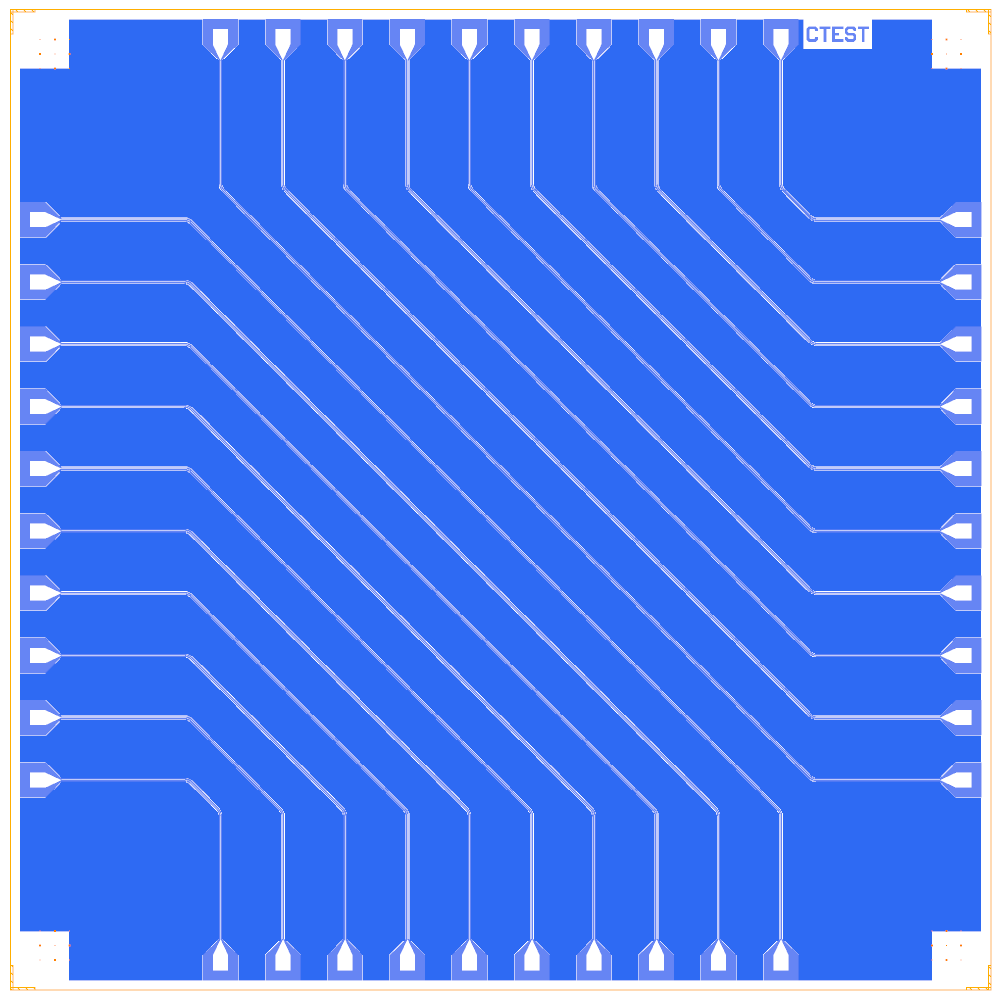

{'PL1': 11135.37, 'PL2': 10237.34, 'PL3': 9339.31, 'PL4': 8441.29, 'PL5': 7543.26, 'PL6': 6645.24, 'PL7': 5747.21, 'PL8': 4849.19, 'PL9': 3951.16, 'PL10': 3053.13, 'PL11': 11135.37, 'PL12': 10237.34, 'PL13': 9339.31, 'PL14': 8441.29, 'PL15': 7543.26, 'PL16': 6645.24, 'PL17': 5747.21, 'PL18': 4849.19, 'PL19': 3951.16, 'PL20': 3053.13}


In [6]:
def corner(ref, shift):                                  # KQC "<port>_corner" (one r inward) + a shift
    x, y, ang = port_info(d, ref)
    return (x + r * math.cos(math.radians(ang)) + shift[0], y + r * math.sin(math.radians(ang)) + shift[1])


with d.batch():
    for i in range(1, 2 * per + 1):                      # KQC _produce_waveguide(i, ∓1200, first, second)
        first, second, dist = ("IN", "OUT", -1200) if i <= per else ("OUT", "IN", 1200)
        a_ref, b_ref = f"PL{i}_{first}.port", f"PL{i}_{second}.port"
        d.route(f"PL{i}", a_ref, b_ref, nodes=[corner(a_ref, (0, dist)), corner(b_ref, (dist, 0))])
snap(d, STEPS / "4_routes.png", box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420)
print({k: round(v, 2) for k, v in d.result.route_lengths().items()})

**Centring, save.** No sim groups: through lines only (a transmission test is an S-parameter measurement, which `sim_tools` does not export). `center_in_die` checks that the content sits centred in the die and shifts it if it is more
than 50 µm off. Then the design is saved.

In [7]:
print("centring shift (µm):", center_in_die(d))
rebuild(d)
DESIGN = d.save(OUT / "sample_holder_test.json")
print(d, "→", DESIGN)

centring shift (µm): (0.0, 0.0)
<Designer sample_holder_test: 40 instances, 20 routes, live=False> → examples\designs\kqc\test_chips\sample_holder_test.json


## 7 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to read. **PDK
design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): flagged,
never enforced — the rebuild keeps the source's choices. `pdk_report` adds the cheese source, the centring
and the junction types.

**Here:** DRC clean: no errors, no warnings (the 20 nested lines do not cross and every launcher port is joined) and no PDK design warning; the 40 `pad_edge` warnings of KQC's positions (outer etch 104 µm) are gone. `pdk_report` gives KQC's grid ("the original design's own"), the content centred (0, 0) and no junctions.

In [8]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

**0 errors · 0 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|

| check | value |
|---|---|
| cheese | the original design's own (or none) |
| content centre − die centre | (+0, +0) µm |
| junction types | — |
| PDK design warnings | 0 (none) |

## 8 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit from the components' LOM models: launchers are 50 Ω ports, a route
between two ports is one conductor (a through line), a route to a shorted end is a λ/4 resonator.

In [9]:
lb = d.lom()
print(lom_summary(lb))
print(netlist_md(lb).split('| branch |')[0])

{'nodes': 20, 'branches': 40, 'controls': 0, 'unconnected': 0}
**21 nodes · 40 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `PL1` | `PL1`, `PL1_IN.pad`, `PL1_OUT.pad` |
| `PL2` | `PL2`, `PL2_IN.pad`, `PL2_OUT.pad` |
| `PL3` | `PL3`, `PL3_IN.pad`, `PL3_OUT.pad` |
| `PL4` | `PL4`, `PL4_IN.pad`, `PL4_OUT.pad` |
| `PL5` | `PL5`, `PL5_IN.pad`, `PL5_OUT.pad` |
| `PL6` | `PL6`, `PL6_IN.pad`, `PL6_OUT.pad` |
| `PL7` | `PL7`, `PL7_IN.pad`, `PL7_OUT.pad` |
| `PL8` | `PL8`, `PL8_IN.pad`, `PL8_OUT.pad` |
| `PL9` | `PL9`, `PL9_IN.pad`, `PL9_OUT.pad` |
| `PL10` | `PL10`, `PL10_IN.pad`, `PL10_OUT.pad` |
| `PL11` | `PL11`, `PL11_OUT.pad`, `PL11_IN.pad` |
| `PL12` | `PL12`, `PL12_OUT.pad`, `PL12_IN.pad` |
| `PL13` | `PL13`, `PL13_OUT.pad`, `PL13_IN.pad` |
| `PL14` | `PL14`, `PL14_OUT.pad`, `PL14_IN.pad` |
| `PL15` | `PL15`, `PL15_OUT.pad`, `PL15_IN.pad` |
| `PL16` | `PL16`, `PL16_OUT.pad`, `PL16_IN.pad` |
| `PL17` | `PL17`, `PL17_OUT.pad`, `PL17_IN.p

## 9 · LOM simulation — not applicable

None: no junctions or resonators (20 × 50 Ω through lines; the lengths are printed in step 6).

## 10 · FEM: send the jobs

One job per sim group and analysis: the group is cut out of the chip with its margin, every line leaving the
box ends in a port, junctions are lumped ports, and the ground grid is removed (simulation exports never have
cheese). The table lists each job's ports and C-matrix nets (named after islands, couplers and routes, so the
result maps back onto the LOM nodes).

With `RUN_FEM = True` and AEDT 2024 R1 (or later) installed, `send_fem_jobs` solves each Ansys job in a **new
batch, non-graphical** AEDT (`solve_job`) — an AEDT window you have open is never touched. The command-line
equivalent is `qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

Here: nothing to export: the chip has no sim groups.

In [10]:
jobs = send_fem_jobs(DESIGN, run=RUN_FEM)
display(Markdown(jobs_md(jobs) if jobs else "No sim groups: no FEM job."))

0 job(s) exported; RUN_FEM is False, nothing solved.


No sim groups: no FEM job.

## 11 · Bring the results back

When a job has been solved its folder holds `results/results.json`. `fem_back` then calls
`fill(model, design, job)`: the C-matrix (or eigenmode) values replace the component estimates branch by
branch (matched by net name), and the table compares the two. `simulate(filled)` re-runs the LOM on the
extracted values. Until then the cell says which jobs are still waiting.

In [11]:
filled, md = fem_back(lb.model, DESIGN, jobs)
display(Markdown(md or "No FEM jobs."))
if filled:
    from quantcore_circuits.lom.simulate import simulate
    key, fc = next(iter(filled.items()))
    display(Markdown(f"**LOM on the FEM values ({key}):**\n\n" + modes_md(simulate(fc, max_modes=2))))

No FEM jobs.

## 12 · Change one property — not applicable

There is no LOM simulation to re-run on this chip (through lines only), so this step has nothing to change and re-simulate.

## 13 · Build and export

**The design file.** `sample_holder_test.json` (saved in step 6) is the whole design: `qcc build
examples/designs/kqc/test_chips/sample_holder_test.json` rebuilds `build/sample_holder_test.oas` + its sidecar, and the KLayout plugin,
`qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the filled 3/0 keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese
hole), no junction layers,
and the frame (100/0, 1000/0, 1001/0). The cheese source is `build`: KQC's grid drawn in the build (`with_grid=True`) stands, and no PDK band is added. In this run: 1/0 844 830 polygons, 3/0 808 845; cheese source `build`, 844 805 holes. Corner rounding (fab only) is skipped unless `FULL_FAB`;
`qcc mask examples/designs/kqc/test_chips/sample_holder_test.json` writes the complete file.

In [12]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 844830 |
| 3/0 | M3 | 808845 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 844805 holes on the mask.

→ `build/sample_holder_test_fab.oas`

## 14 · Snapshots

The snapshots of the source notebook (full chip and its zooms; the die frame's south-west corner, dicing L on
1000/0 and the 3 × 3 alignment grid on 1001/0) and two east-side launchers in the **fab view** (the mask from step 13: 1/0
and 3/0 with the grid holes). KQC's grid fills the ground as one tone at full-chip scale; the chip boundary 100/0
is drawn as an outline.

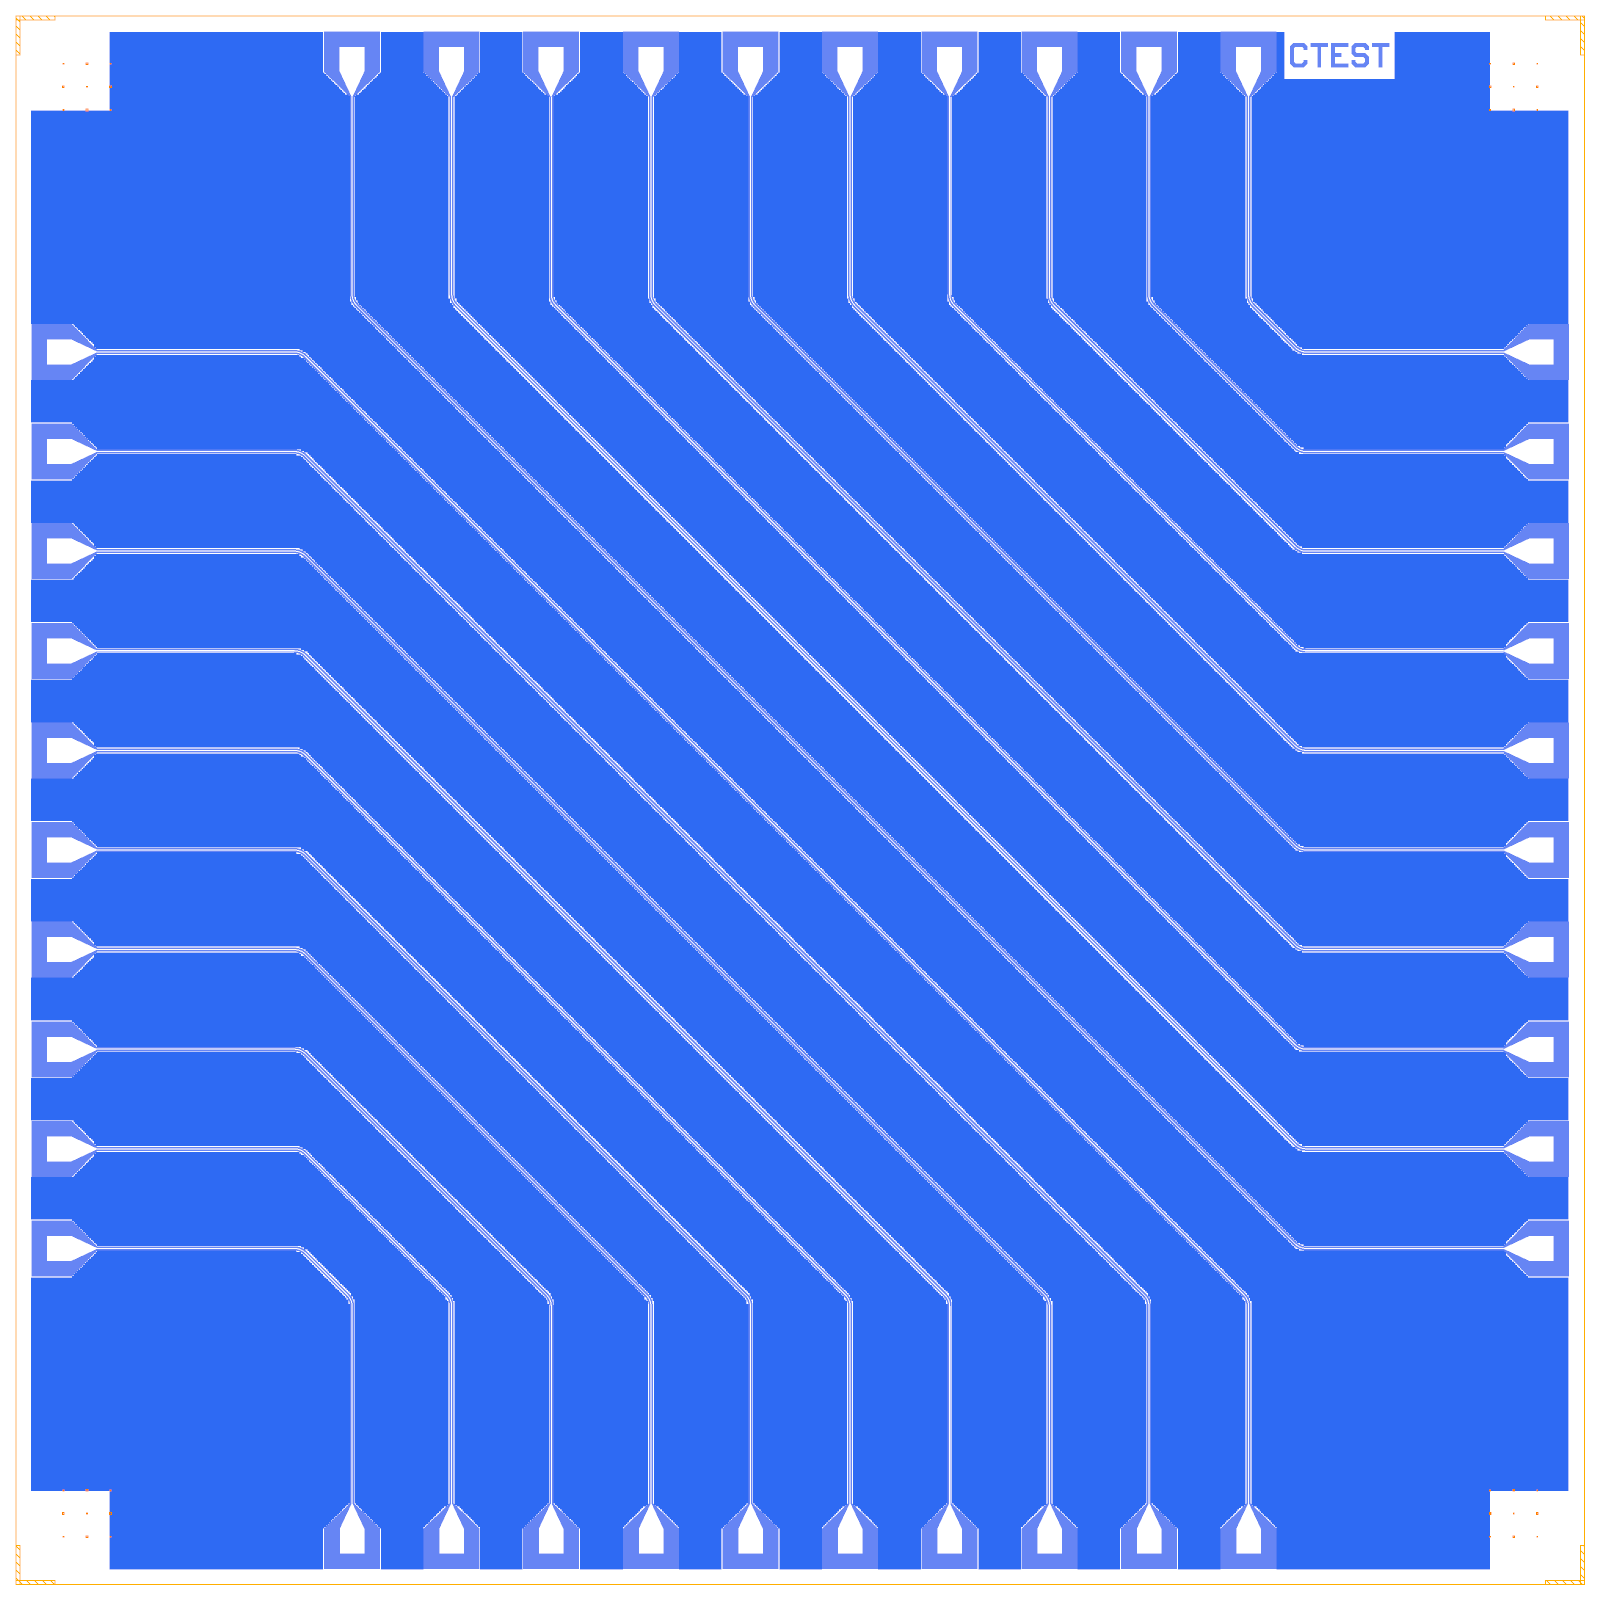

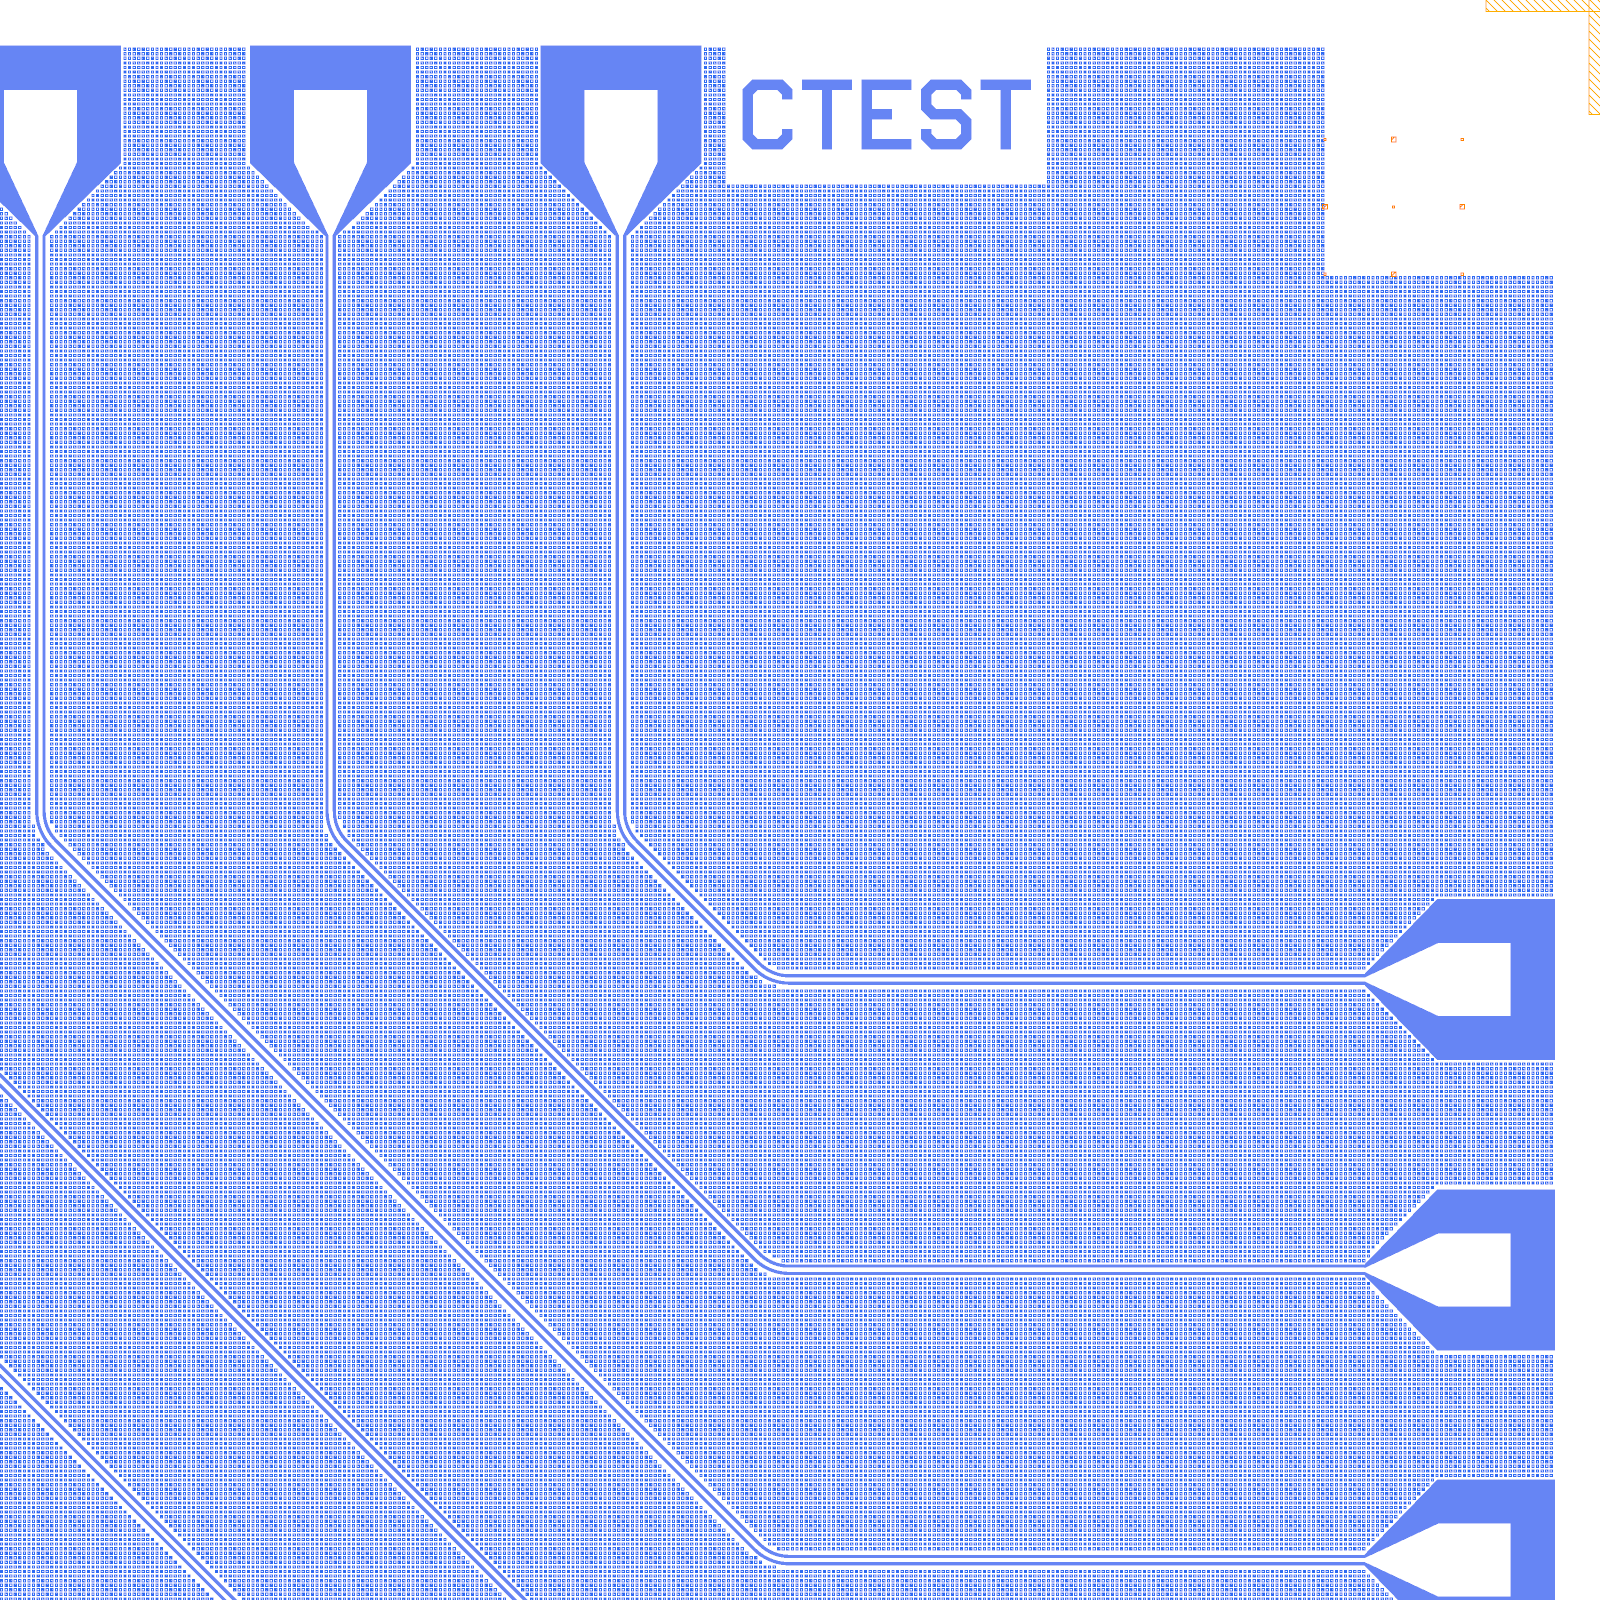

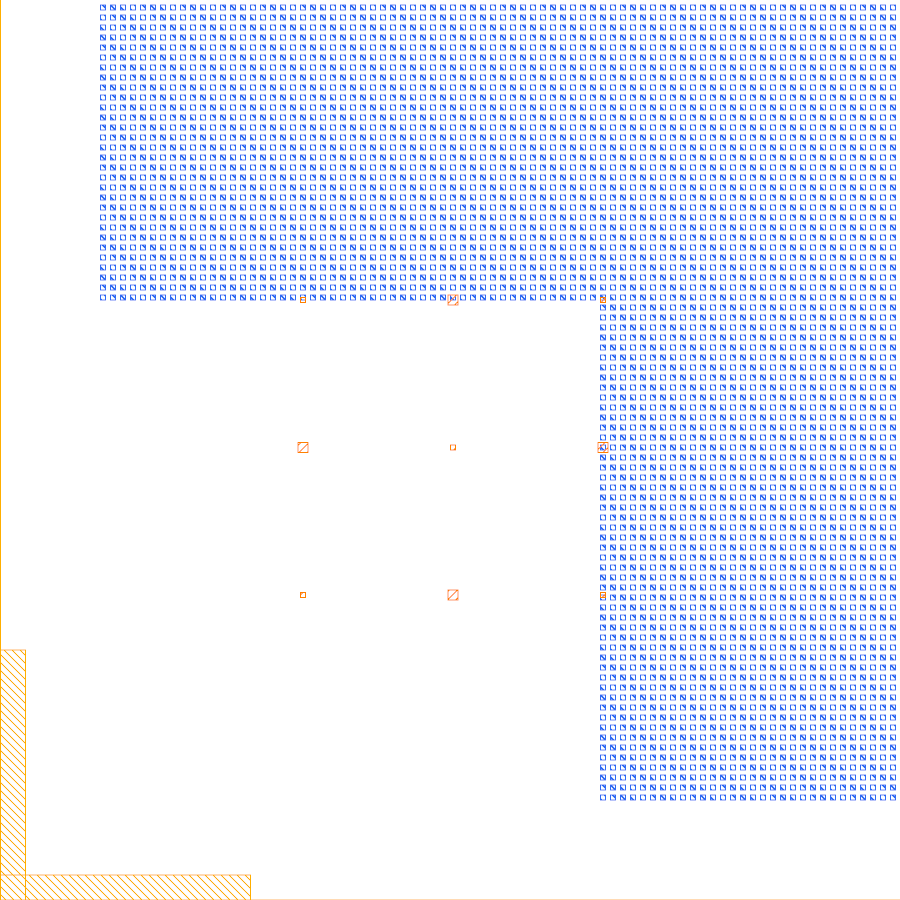

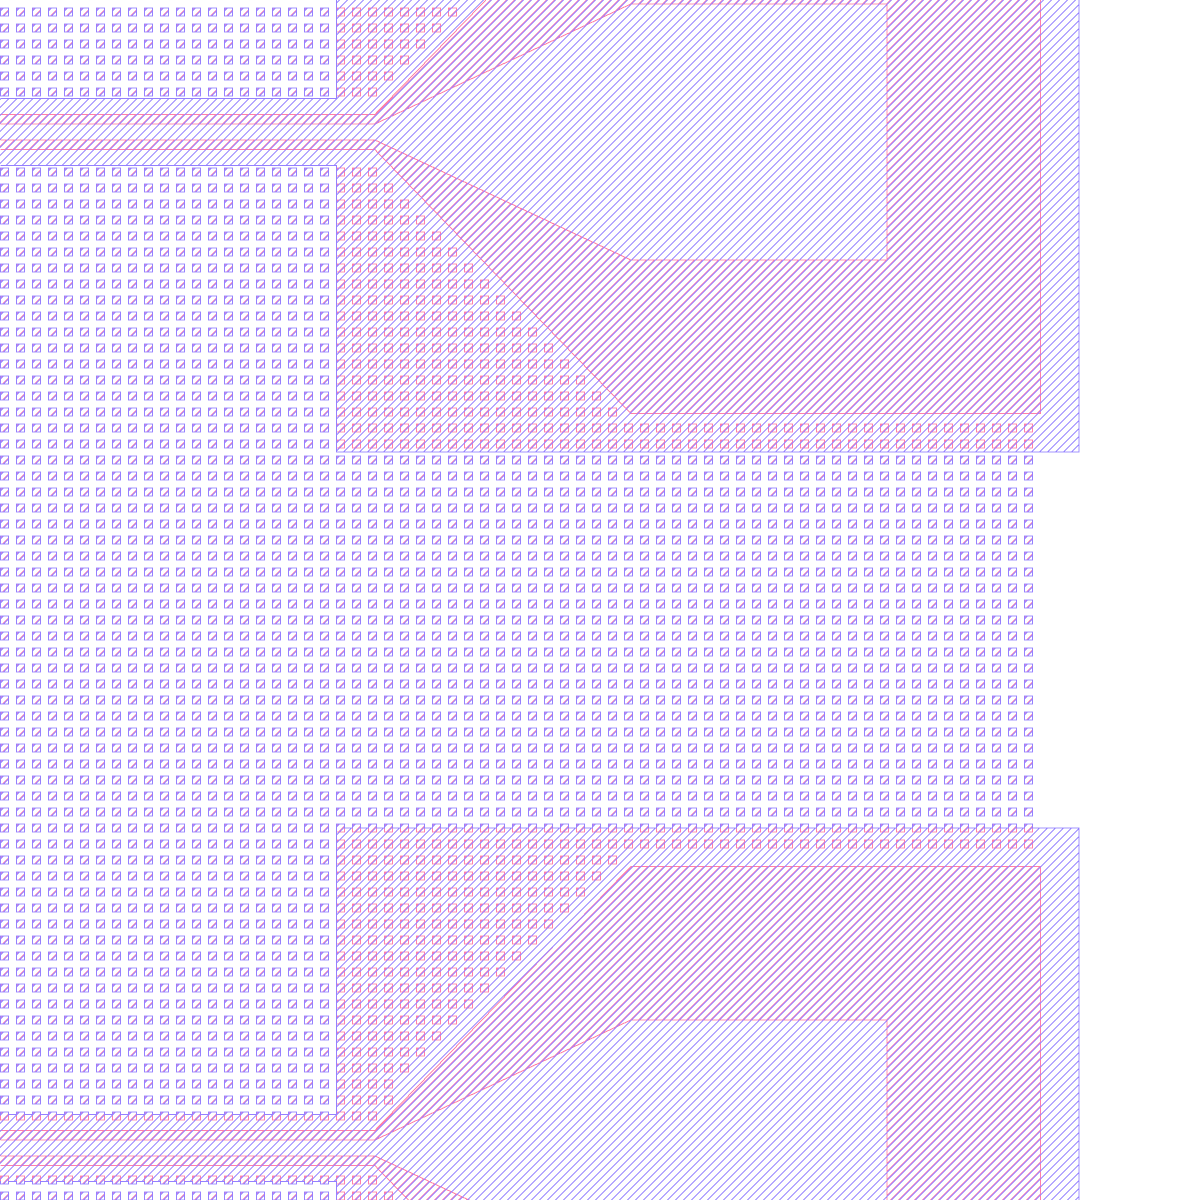

In [13]:
show_snapshot(d, OUT / "sample_holder_test.png", box=(-100, -100, 10100, 10100))
show_snapshot(d, OUT / "sample_holder_test_corner.png", box=(6500, 6500, 10000, 10000), width=480)
show_snapshot(d, OUT / "sample_holder_test_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
snap_file(Path("build") / "sample_holder_test_fab.oas", OUT / "sample_holder_test_fab.png", box=(9250, 4650, 10000, 5400), size=(1200, 1200), width=420);

**Reference: XOR with the source.** KQC's chip built stand-alone, XOR-ed layer by layer with this build (the union
of both layer sets; `refpoints`, `ports` and the `instance_names` label layer are annotation and are skipped). The
reference gets `name_brand="QC"`; with KQC's default "IQM" the frame text adds its area (last line). The column
"> 1 nm" is the XOR shrunk by one database unit. **The rebuild is expected to differ** by design: the frame (KQC's
ChipFrame vs the Quantcore die frame), the ground grid (KQC's stand-alone build has none) and the launchers moved 4 µm out with their lines' first legs. A reference, not a pass/fail check.

In [14]:
import klayout.db as kdb
from kqcircuits.chips.sample_holder_test import SampleHolderTest as KqcChip


def xor_vs_kqc(**ref_params):
    ref = pya.Layout()
    ref_top = ref.create_cell("ref")
    ref_top.insert(pya.DCellInstArray(KqcChip.create(ref, **ref_params).cell_index(), pya.DTrans()))
    ly = kdb.Layout()
    ly.read(str(d.out))
    top = ly.top_cell()
    mine = {ly.get_info(i).name: i for i in ly.layer_indexes()}
    theirs = {ref.get_info(i).name: i for i in ref.layer_indexes()}
    rows = []
    for name in sorted(set(mine) | set(theirs)):
        if not name or name in ("refpoints", "instance_names", "ports"):
            continue
        a = kdb.Region(ref_top.begin_shapes_rec(theirs[name])).merged() if name in theirs else kdb.Region()
        b = kdb.Region(top.begin_shapes_rec(mine[name])).merged() if name in mine else kdb.Region()
        if a.is_empty() and b.is_empty():
            continue
        x = a ^ b
        rows.append((name, x.area() * ref.dbu ** 2, x.sized(-1).area() * ref.dbu ** 2,
                     None if x.is_empty() else x.bbox().to_dtype(ref.dbu)))
    return rows


rows = xor_vs_kqc(name_brand="QC")
table = ["| layer | XOR area (µm²) | > 1 nm (µm²) | where |", "|---|---|---|---|"]
table += [f"| {n} | {x:.3g} | {y:.3g} | {w or ''} |" for n, x, y, w in rows]
total, real = sum(r[1] for r in rows), sum(r[2] for r in rows)
iqm = sum(r[1] for r in xor_vs_kqc())
display(Markdown("\n".join(table) + f"\n\n**Total XOR area: {total:.3g} µm²** ({real:.3g} µm² wider than 1 nm). "
                 f"Against KQC's default brand text \"IQM\": {iqm:.3g} µm²."))

| layer | XOR area (µm²) | > 1 nm (µm²) | where |
|---|---|---|---|
| 1t1_airbridge_flyover | 2.81e+05 | 2.81e+05 | (788,788;9212,9212) |
| 1t1_airbridge_pads | 5.4e+05 | 5.4e+05 | (788,788;9212,9212) |
| 1t1_base_metal_gap_for_EBL | 8.6e+06 | 8.6e+06 | (0,0;10000,10000) |
| 1t1_base_metal_gap_wo_grid | 8.31e+06 | 8.31e+06 | (0,0;10000,10000) |
| 1t1_chip_dicing | 2.68e+05 | 2.68e+05 | (-5,-5;10005,10005) |
| 1t1_ground_grid | 2.11e+07 | 2.11e+07 | (100,100;9895,9895) |
| 1t1_ground_grid_avoidance | 1.14e+07 | 1.14e+07 | (-5,-5;10005,10005) |
| 1t1_waveguide_path | 5.11e+05 | 5.1e+05 | (516,516;9484,9484) |
| qcc_chip_boundary | 1e+08 | 1e+08 | (0,0;10000,10000) |
| qcc_marker_0 | 4.75e+04 | 4.75e+04 | (0,0;10000,10000) |
| qcc_marker_1 | 2.1e+03 | 2.1e+03 | (297.5,300;9702.5,9700) |

**Total XOR area: 1.51e+08 µm²** (1.51e+08 µm² wider than 1 nm). Against KQC's default brand text "IQM": 1.51e+08 µm².

**Here:** the XOR (1.5 × 10⁸ µm²) is all from the expected differences: the qcc frame layers (the boundary layer covers the die, 1 × 10⁸ µm², plus the markers), the ground grid (2.1 × 10⁷ µm²) and its avoidance, KQC's frame (EBL, dicing and airbridge-marker layers), and the launchers' 4 µm shift on the base etch and the waveguide path.

## 15 · Summary

| | |
|---|---|
| **matches the source** | KQC's cells with their parameters, positions and paths; KQC's whole-area ground grid |
| **differs (PDK)** | the Quantcore die frame instead of KQC's ChipFrame; the 40 launchers 4 µm further out (outer etch 100 µm, `frame.pad_edge`), the lines' end legs with them; sapphire |
| **PDK design warnings** | as listed in step 7 |
| **FEM** | no sim groups, no jobs |